# Modelagem sobre um TARGET desbalanceado

Este notebook dá continuidade ao `demo_criacao_target.ipynb`, que discutiu como construir a variável TARGET para o dataset de aprovação de cartão de crédito (`rikdifos/credit-card-approval-prediction`, o mesmo do Tech Challenge Fase 2) a partir de dois critérios de atraso. A conclusão daquele notebook foi que o critério **rígido** (atraso de 60 dias ou mais, isolando inadimplência grave ou persistente) é o que faz sentido de negócio para este problema — e que o desbalanceamento resultante (nos dados reais, algo perto de 98% de bons pagadores contra menos de 2% de maus pagadores) é uma consequência esperada dessa escolha, não um defeito a corrigir na definição do TARGET.

Este notebook parte exatamente daí. Ele reconstrói o TARGET com o critério rígido — sem reabrir a discussão sobre qual critério usar, isso já foi decidido — e demonstra o pipeline completo de modelagem sobre um problema fortemente desbalanceado: divisão treino/teste, comparação de estratégias de tratamento de desbalanceamento, otimização de hiperparâmetros com validação cruzada, e avaliação final usando métricas que de fato refletem o desempenho na classe rara. O fio condutor é o mesmo do notebook anterior, agora aplicado à etapa de modelagem: o desbalanceamento é um dado do problema, e a resposta correta é tratá-lo com a técnica certa na hora certa — não maquiar o TARGET, nem otimizar por uma métrica (acurácia) que ignora exatamente a classe que importa. Ao longo do caminho, também vamos confrontar diretamente alguns resultados contraintuitivos que esse tipo de pipeline produz na prática — inclusive quando a técnica "mais sofisticada" (SMOTE) não vence, e quando a métrica de busca escolhida não maximiza a métrica que o argumento de negócio diz importar mais. Esse tipo de tensão não é um erro a esconder; é parte do que este notebook quer ensinar.

Há ainda um terceiro fio, que não estava no plano original e que mudou o notebook no meio do caminho: ao inspecionar a base com mais cuidado, descobrimos que ela está cheia de **perfis duplicados** — clientes com IDs diferentes mas cadastro idêntico ao dia, quase certamente a mesma pessoa. Isso não é um detalhe: um split treino/teste aleatório deixa "gêmeos" dos dois lados, e o modelo aparenta prever o que na verdade está apenas memorizando. Corrigir isso (com um split e uma validação cruzada cientes de grupo) derruba as métricas para um patamar bem menos confortável — e é esse patamar honesto, não o inflado, que este notebook reporta. A lição final é dura, mas é a lição certa: nenhuma técnica de balanceamento cria sinal que não existe nos atributos.

## Onde colocar os dados

Assim como o notebook anterior, este é standalone e assume a convenção de pastas do template `drlima/postech-tech-challenge-fase2-template`: execução a partir de uma pasta `notebooks/`, com os dados brutos em `../data/raw/`:

```
projeto/
├── data/
│   └── raw/
│       ├── application_record.csv
│       └── credit_record.csv
└── notebooks/
    └── demo_modelagem_desbalanceada.ipynb
```

Os arquivos vêm do dataset [rikdifos/credit-card-approval-prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction) no Kaggle. Se for executar fora dessa estrutura, baixe os dois CSVs e ajuste `DATA_DIR` na célula abaixo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedGroupKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
)

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
# RANDOM_STATE é usado em TODO ponto com aleatoriedade neste notebook: o split
# treino/teste, o SMOTENC, o RandomForest e o StratifiedKFold da busca de
# hiperparâmetros. Uma ressalva importante, discutida com números mais adiante:
# com n_jobs=-1 (paralelismo), o RANDOM_STATE garante que as MESMAS decisões
# sejam tomadas (mesmos splits, mesmos hiperparâmetros sorteados, mesma
# estratégia vencedora) — mas não garante reprodutibilidade bit-a-bit das
# métricas de classificação em outra máquina, por causa da ordem de agregação
# em ponto flutuante entre threads.

DATA_DIR = Path("../data/raw")
APPLICATION_PATH = DATA_DIR / "application_record.csv"
CREDIT_PATH = DATA_DIR / "credit_record.csv"

for path in (APPLICATION_PATH, CREDIT_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado em {path.resolve()}. "
            "Ajuste DATA_DIR para o diretório correto dos CSVs."
        )

print("Diretório de dados:", DATA_DIR.resolve())

Diretório de dados: /home/drl/fiap/dtat/2dtat-bb/data/raw


## Reconstruindo o TARGET (critério rígido)

Reaproveitamos aqui a mesma lógica do notebook anterior: consolidar por cliente (`groupby("ID").max()`) uma flag de atraso de 60 dias ou mais (`STATUS` em `['2', '3', '4', '5']`), e fazer o merge (`inner`) com `application_record.csv` para obter os atributos preditores. O notebook anterior discute em detalhe as implicações dessa escolha — inclusive o viés de seleção introduzido pelo `inner join` (só entram clientes que já tiveram crédito aprovado) e o viés de exposição da agregação "ever" — e essas limitações continuam valendo aqui; não vamos repeti-las em profundidade porque o foco deste notebook é a etapa de modelagem, não a definição do TARGET.

In [2]:
credit_record = pd.read_csv(CREDIT_PATH)
application_record_raw = pd.read_csv(APPLICATION_PATH)

credit_record["bad_rigido"] = credit_record["STATUS"].isin(["2", "3", "4", "5"]).astype(int)
target_rigido = (
    credit_record.groupby("ID")["bad_rigido"]
    .max()
    .reset_index()
    .rename(columns={"bad_rigido": "TARGET"})
)

application_record = application_record_raw.drop_duplicates(subset="ID", keep="first")
base = application_record.merge(target_rigido, on="ID", how="inner")

print("Clientes na base:", len(base))
print("Taxa de mau pagador (TARGET=1):", f"{base['TARGET'].mean():.4%}")
base["TARGET"].value_counts(normalize=True)

Clientes na base: 36457
Taxa de mau pagador (TARGET=1): 1.6897%


0    0.983103
1    0.016897
Name: TARGET, dtype: float64

## Pré-processamento mínimo

O objetivo deste notebook é a modelagem, não engenharia de atributos — então o pré-processamento aqui é deliberadamente enxuto, só o suficiente para ter uma matriz numérica pronta para os classificadores:

- **`DAYS_BIRTH`** vem em dias negativos a partir da data de referência; convertido para **idade em anos** (`idade_anos = -DAYS_BIRTH / 365.25`).
- **`DAYS_EMPLOYED`** também vem em dias negativos, mas usa um código-sentinela especial, `365243`, para representar clientes sem vínculo empregatício ativo (aposentados, por exemplo) — um valor claramente fora de escala se tratado como dias normais. Criamos uma flag binária `flag_sem_emprego_ativo` para esses casos, e calculamos `anos_empregado` normalmente para o restante, zerando-o onde a flag é 1.
- **`FLAG_MOBIL`** é constante (sempre `1` para todos os clientes) — não carrega nenhum poder preditivo, então é descartada.
- **Categóricas binárias** (`CODE_GENDER`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`) viram `0`/`1` diretamente.
- **Categóricas com mais de duas classes** (`NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`, `NAME_HOUSING_TYPE`, `OCCUPATION_TYPE`) recebem one-hot encoding simples (`pd.get_dummies`, descartando a primeira categoria de cada uma para evitar redundância). `OCCUPATION_TYPE` tem um volume relevante de nulos (ausência de ocupação registrada, majoritariamente aposentados) — preenchidos com a categoria explícita `"Nao_informado"` em vez de descartados.

Uma ressalva sobre a ordem das operações: o `pd.get_dummies` abaixo roda sobre a base inteira, **antes** do split treino/teste que vem na próxima seção. Isso não é vazamento de rótulo — `get_dummies` não usa a variável TARGET nem nenhuma estatística ajustada no treino, ao contrário de, por exemplo, um `StandardScaler` ajustado antes do split ou de um target encoding. Mas ainda quebra o isolamento estrito entre treino e teste: se uma categoria rara existisse só de um lado do split, o vocabulário de colunas ficaria inconsistente. Neste dataset isso não chega a ser um problema — todas as categorias das 5 colunas multiclasse aparecem nos dois lados do split, e a mais rara delas (`NAME_INCOME_TYPE_Student`) representa só ~0,03% da base (cerca de 11 clientes) — mas é uma fragilidade real: com outro `random_state`, ou em produção com dados novos, essa "sorte" não está garantida. A forma mais rigorosa seria mover o split para antes do encoding e usar `OneHotEncoder(handle_unknown="ignore")` ajustado só no treino; mantivemos `get_dummies` aqui por simplicidade, mas vale ter essa fragilidade em mente.

Nenhuma normalização/padronização é aplicada às variáveis de entrada do classificador porque o modelo usado (`RandomForestClassifier`) é baseado em árvores e não depende da escala das variáveis. Isso vale para o classificador — mas **não vale para o SMOTE**, como discutimos na próxima seção.

In [3]:
df = base.copy()

df["idade_anos"] = -df["DAYS_BIRTH"] / 365.25

df["flag_sem_emprego_ativo"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["anos_empregado"] = np.where(
    df["flag_sem_emprego_ativo"] == 1, 0.0, -df["DAYS_EMPLOYED"] / 365.25
)

df["CODE_GENDER"] = (df["CODE_GENDER"] == "M").astype(int)  # 1 = M, 0 = F
df["FLAG_OWN_CAR"] = (df["FLAG_OWN_CAR"] == "Y").astype(int)
df["FLAG_OWN_REALTY"] = (df["FLAG_OWN_REALTY"] == "Y").astype(int)
df["OCCUPATION_TYPE"] = df["OCCUPATION_TYPE"].fillna("Nao_informado")

categoricas_multiclasse = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
]
df_enc = pd.get_dummies(df, columns=categoricas_multiclasse, drop_first=True)

colunas_para_descartar = ["ID", "DAYS_BIRTH", "DAYS_EMPLOYED", "FLAG_MOBIL", "TARGET"]
X = df_enc.drop(columns=colunas_para_descartar)
y = df_enc["TARGET"]

print("X shape:", X.shape)
print("Todas as colunas são numéricas:", (X.dtypes != "object").all())

X shape: (36457, 47)
Todas as colunas são numéricas: True


## Um problema escondido nos dados: perfis duplicados

Antes de dividir treino e teste, vale fazer uma pergunta que raramente é feita: quantos desses 36 mil "clientes" são de fato pessoas diferentes? O `application_record.csv` traz renda exata, data de nascimento em dias e tempo de emprego em dias — três valores que, combinados com as demais colunas, dificilmente coincidem por acaso entre duas pessoas distintas. Vamos agrupar os clientes por cadastro idêntico (todas as colunas, exceto o `ID`) e ver o que aparece.

In [4]:
colunas_cadastro = [c for c in application_record.columns if c != "ID"]
base["grupo_perfil"] = pd.util.hash_pandas_object(base[colunas_cadastro].astype(str), index=False).values

tamanho_grupo = base.groupby("grupo_perfil")["ID"].transform("size")
print("Clientes na base:                ", len(base))
print("Perfis de cadastro distintos:    ", base["grupo_perfil"].nunique())
print("Clientes com ao menos um 'gêmeo':", int((tamanho_grupo > 1).sum()), f"({(tamanho_grupo > 1).mean():.1%})")
print("Maior grupo de gêmeos:           ", int(tamanho_grupo.max()), "clientes")

por_grupo = base.groupby("grupo_perfil")["TARGET"].agg(["size", "sum"])
conflitantes = por_grupo[(por_grupo["sum"] > 0) & (por_grupo["sum"] < por_grupo["size"])]
print()
print("Grupos com rótulos CONFLITANTES (mesmo cadastro, TARGET diferente):", len(conflitantes))
print(f"Positivos dentro desses grupos: {int(conflitantes['sum'].sum())} de {int(base['TARGET'].sum())} "
      f"({conflitantes['sum'].sum() / base['TARGET'].sum():.1%} de todos os maus pagadores)")

# Um exemplo concreto de grupo conflitante
exemplo = base[base["grupo_perfil"] == conflitantes.index[0]]
exemplo[["ID", "CODE_GENDER", "AMT_INCOME_TOTAL", "DAYS_BIRTH", "DAYS_EMPLOYED", "OCCUPATION_TYPE", "TARGET"]]

Clientes na base:                 36457
Perfis de cadastro distintos:     9728
Clientes com ao menos um 'gêmeo': 33320 (91.4%)
Maior grupo de gêmeos:            51 clientes

Grupos com rótulos CONFLITANTES (mesmo cadastro, TARGET diferente): 269
Positivos dentro desses grupos: 419 de 616 (68.0% de todos os maus pagadores)


,ID,CODE_GENDER,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,TARGET
30804,5126121,F,72000.0,-15185,-227,Medicine staff,0
30805,5126122,F,72000.0,-15185,-227,Medicine staff,0
30806,5126123,F,72000.0,-15185,-227,Medicine staff,0
30807,5126124,F,72000.0,-15185,-227,Medicine staff,0
30808,5126125,F,72000.0,-15185,-227,Medicine staff,0
30809,5126126,F,72000.0,-15185,-227,Medicine staff,0
30810,5126127,F,72000.0,-15185,-227,Medicine staff,0
30811,5126128,F,72000.0,-15185,-227,Medicine staff,1


Os números são difíceis de contornar: **91% dos clientes têm pelo menos um gêmeo de cadastro idêntico**, e os 36 mil IDs correspondem a menos de 10 mil perfis distintos. Repare no exemplo acima: IDs consecutivos, mesma pessoa em todas as colunas (nascida no mesmo dia, empregada há exatamente o mesmo número de dias, mesma renda), e um deles é mau pagador enquanto os outros não. Isso tem duas consequências diretas para a modelagem:

1. **Teto estrutural.** 68% dos maus pagadores têm um gêmeo idêntico que é bom pagador. Nenhum modelo que use só o cadastro consegue separar esses pares — eles têm exatamente os mesmos atributos de entrada. Isso limita, por construção, o quão bom qualquer modelo pode ser aqui.
2. **Vazamento no split.** Se dividirmos treino e teste aleatoriamente, quase todo cliente do teste terá um gêmeo no treino. Um modelo flexível (uma Random Forest com folhas pequenas, por exemplo) memoriza o gêmeo do treino e "acerta" o do teste — e as métricas passam a medir memorização, não capacidade de generalizar para pessoas novas.

A correção para o segundo problema é conhecida: o split precisa ser **por grupo**, de modo que todos os clientes de um mesmo perfil fiquem do mesmo lado. O primeiro problema não tem correção dentro deste notebook — só com outras fontes de informação, tema do notebook seguinte.

## Divisão treino/teste — por grupo, e antes de qualquer tratamento de desbalanceamento

A ordem das operações importa aqui, e vale deixar explícito por quê: o split treino/teste precisa acontecer **antes** de qualquer técnica de balanceamento (`class_weight`, SMOTE, ou qualquer reamostragem). Se aplicássemos SMOTE, por exemplo, sobre a base inteira e só depois separássemos treino e teste, corremos o risco de que exemplos sintéticos gerados a partir de um cliente que caiu no teste influenciem exemplos que caíram no treino (ou vice-versa) — um vazamento de informação entre treino e teste que infla artificialmente as métricas.

Usamos `StratifiedGroupKFold` em vez de um `train_test_split` simples, por dois motivos combinados. *Estratificado*, para que a proporção de mau pagador seja preservada nos dois conjuntos (com uma classe tão rara, um split puramente aleatório poderia por azar concentrar a maior parte dos poucos positivos em um dos lados). *Por grupo*, pelo que vimos na seção anterior: todos os clientes de um mesmo perfil de cadastro ficam do mesmo lado, e o teste passa a conter apenas pessoas que o modelo nunca viu. Tomamos um dos 5 folds como teste (~20%) e o restante como treino. E, ponto igualmente importante: o **conjunto de teste nunca é balanceado artificialmente** — ele preserva a proporção real de ~98%/2% do problema, porque é sobre essa realidade que o modelo será avaliado. Só o conjunto de treino é candidato a qualquer tratamento de desbalanceamento, nas seções seguintes.

In [5]:
grupos = base["grupo_perfil"]

divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(divisor.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print("Treino:", X_train.shape, f"— taxa de mau pagador: {y_train.mean():.4%}")
print("Teste: ", X_test.shape, f"— taxa de mau pagador: {y_test.mean():.4%}")
print("Positivos no treino:", int(y_train.sum()), "| no teste:", int(y_test.sum()))
print("Clientes do teste com gêmeo no treino:", f"{grupos.iloc[idx_test].isin(set(grupos_train)).mean():.0%}")

Treino: (29053, 47) — taxa de mau pagador: 1.6418%
Teste:  (7404, 47) — taxa de mau pagador: 1.8774%
Positivos no treino: 477 | no teste: 139
Clientes do teste com gêmeo no treino: 0%


### Quanto o split aleatório inflaria as métricas?

Antes de seguir, vale medir o tamanho do problema que acabamos de evitar. Treinamos o mesmo modelo (`RandomForestClassifier` com `class_weight="balanced"`, o mesmo que será usado nas comparações a seguir) de duas formas: com um `train_test_split` estratificado comum, e com o split por grupo acima. Tudo o mais é idêntico.

In [6]:
def metricas_completas(modelo, X_tr, y_tr, X_te, y_te):
    modelo.fit(X_tr, y_tr)
    proba = modelo.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "recall (mau pagador)": recall_score(y_te, pred),
        "precision (mau pagador)": precision_score(y_te, pred, zero_division=0),
        "f1 (mau pagador)": f1_score(y_te, pred),
        "ROC-AUC": roc_auc_score(y_te, proba),
        "average precision": average_precision_score(y_te, proba),
    }


Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
gemeos_aleatorio = grupos.loc[Xa_test.index].isin(set(grupos.loc[Xa_train.index])).mean()
print(f"Split aleatório: {gemeos_aleatorio:.0%} dos clientes do teste têm um gêmeo idêntico no treino")

comparacao_split = pd.DataFrame({
    "split aleatório (gêmeos vazam)": metricas_completas(
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        Xa_train, ya_train, Xa_test, ya_test),
    "split por grupo (honesto)": metricas_completas(
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        X_train, y_train, X_test, y_test),
}).T
comparacao_split.round(4)

Split aleatório: 89% dos clientes do teste têm um gêmeo idêntico no treino


,recall (mau pagador),precision (mau pagador),f1 (mau pagador),ROC-AUC,average precision
split aleatório (gêmeos vazam),0.3984,0.1984,0.2649,0.7838,0.1624
split por grupo (honesto),0.0144,0.0741,0.0241,0.6091,0.0531


A diferença não é de ajuste fino — é de natureza. Com o split aleatório, 89% do teste tem um gêmeo no treino, e a mesma Random Forest aparenta um recall de 40% e um ROC-AUC de 0,78. Com o split por grupo, o recall cai para pouco mais de 1% e o ROC-AUC para 0,61 — perto do que um sorteio faria. Todo o "desempenho" da primeira coluna era memorização de perfis repetidos. Daqui em diante, **todos os números deste notebook usam o split por grupo**: eles são bem menos animadores, e é exatamente por isso que são os que valem.

## Por que SMOTE "puro" não é apropriado nesta matriz de atributos

Antes de comparar estratégias de balanceamento, vale explicar o que o SMOTE faz de fato — porque essa mecânica tem uma consequência técnica real sobre como ele deve ser usado aqui. SMOTE (*Synthetic Minority Oversampling Technique*) gera exemplos sintéticos da classe minoritária escolhendo um ponto real dessa classe, localizando seus `k` vizinhos mais próximos (também da classe minoritária) no espaço de atributos, e interpolando linearmente entre o ponto e um vizinho sorteado para criar um novo ponto "intermediário". Duas palavras-chave aparecem com frequência a partir daqui: `k_neighbors` é quantos vizinhos entram nessa busca, e `sampling_strategy` é a proporção final desejada entre minoria e maioria (`sampling_strategy=0.5`, por exemplo, não significa "50/50" — significa "a classe minoritária passa a ter a metade do tamanho da majoritária").

O problema: essa interpolação depende de uma noção de distância entre pontos, e nossa matriz `X` tem 47 colunas de natureza muito diferente — 5 contínuas (`AMT_INCOME_TOTAL`, `CNT_CHILDREN`, `CNT_FAM_MEMBERS`, `idade_anos`, `anos_empregado`) e 42 binárias/dummy (0 ou 1). Isso gera dois problemas concretos, não hipotéticos:

1. **Domínio de escala.** O desvio-padrão de `AMT_INCOME_TOTAL` é da ordem de 100 mil, enquanto o desvio-padrão médio das colunas dummy é da ordem de 0,25 — uma diferença de mais de 400 mil vezes. Como a distância euclidiana soma o quadrado de cada diferença, a busca por "vizinho mais próximo" do SMOTE seria decidida quase inteiramente pela renda, e as 42 colunas binárias/dummy contribuiriam de forma praticamente nula.
2. **Interpolação inválida em colunas categóricas.** O SMOTE "clássico" não sabe que uma coluna dummy só pode valer 0 ou 1 — ele interpola normalmente, gerando valores fracionários (ex.: `NAME_EDUCATION_TYPE_Higher education = 0,43`) que não correspondem a nenhuma categoria real.

A correção tem duas partes. Primeiro, usamos `SMOTENC` (*SMOTE for Nominal and Continuous*), uma variante do `imbalanced-learn` desenhada exatamente para esse cenário: ela recebe explicitamente quais colunas são categóricas (`categorical_features`) e, para essas colunas, usa a moda entre os vizinhos em vez de interpolar — nunca gera um valor fracionário impossível. Segundo, para que a busca de vizinhos nas colunas *contínuas* não seja dominada pela renda, padronizamos essas 5 colunas (`StandardScaler`, média 0 e desvio-padrão 1) antes do SMOTENC — o que é seguro porque, embora o `RandomForestClassifier` não precise de escala nenhuma (ele só compara valores de uma mesma coluna entre si, então uma transformação monotônica não muda em nada suas decisões de split), o SMOTENC sim depende de escala, por ser baseado em distância. São duas ferramentas com necessidades diferentes dentro do mesmo pipeline.

In [7]:
continuous_cols = ["CNT_CHILDREN", "AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS", "idade_anos", "anos_empregado"]
n_continuous = len(continuous_cols)

# Máscara booleana na MESMA ordem de colunas que o ColumnTransformer produz:
# as contínuas (agora padronizadas) primeiro, seguidas por todas as demais
# colunas (binárias e dummies) na ordem original — daí False para as 5
# primeiras posições e True para o restante.
categorical_mask = [False] * n_continuous + [True] * (X.shape[1] - n_continuous)

scaler = ColumnTransformer(
    [("num", StandardScaler(), continuous_cols)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
scaler.set_output(transform="pandas")

print("Colunas contínuas padronizadas:", continuous_cols)
print("Colunas tratadas como categóricas pelo SMOTENC:", sum(categorical_mask), "de", len(categorical_mask))

Colunas contínuas padronizadas: ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'idade_anos', 'anos_empregado']
Colunas tratadas como categóricas pelo SMOTENC: 42 de 47


## Comparando estratégias de balanceamento

Antes de comparar, duas definições rápidas que vamos usar o tempo todo a partir daqui: **recall** é, dos clientes que de fato são maus pagadores, quantos o modelo conseguiu identificar; **precision** é, dos clientes que o modelo marcou como maus pagadores, quantos realmente eram; **f1** é a média harmônica dos dois — um resumo que só fica alto quando ambos estão razoavelmente altos.

Comparamos três abordagens, todas usando o mesmo modelo base (`RandomForestClassifier`, sem tuning de hiperparâmetros ainda) para que a comparação isole o efeito da técnica de balanceamento, não diferenças entre modelos:

1. **Baseline** — nenhum tratamento de desbalanceamento. O modelo vê os dados de treino exatamente como estão (~98%/2%).
2. **`class_weight="balanced"`** — o próprio classificador pondera o erro cometido em cada classe pelo inverso da sua frequência, sem alterar os dados de treino.
3. **SMOTENC** — gera exemplos sintéticos da classe minoritária no espaço de atributos (contínuos padronizados + categóricos tratados corretamente, como explicado acima), dentro de um `Pipeline` do `imbalanced-learn` (não do `scikit-learn` puro). Isso é deliberado: um `Pipeline` comum aplicaria o SMOTENC uma vez, sobre o treino inteiro, e depois faria validação cruzada sobre esse treino já reamostrado — vazando informação sintética entre os folds. O `Pipeline` do `imblearn` refaz o SMOTENC **dentro de cada fold**, usando só os dados daquele fold.

Nas três abordagens, o SMOTENC e o `class_weight` são aplicados **apenas ao treino** — o teste, criado na seção anterior, permanece intocado e com a proporção real do problema. Usamos aqui o comportamento padrão do SMOTENC (`sampling_strategy="auto"`, que equilibra a classe minoritária até igualar a majoritária): com 477 positivos reais no treino contra 28.576 negativos, isso significa gerar 28.099 exemplos sintéticos — quase 59 exemplos fabricados para cada exemplo real da classe minoritária. É um volume grande, e vale ter isso em mente ao interpretar o ganho de recall que o SMOTENC proporciona: parte dele vem de dados fabricados por interpolação, não de mais exemplos reais observados.

In [8]:
def avaliar(modelo, nome, X_train, y_train, X_test, y_test):
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    return {
        "estratégia": nome,
        "recall (mau pagador)": recall_score(y_test, y_pred),
        "precision (mau pagador)": precision_score(y_test, y_pred, zero_division=0),
        "f1 (mau pagador)": f1_score(y_test, y_pred),
        "acurácia": accuracy_score(y_test, y_pred),
        "identificados (VP)": int(((y_pred == 1) & (y_test == 1)).sum()),
        "sinalizados": int((y_pred == 1).sum()),
    }


baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
resultado_baseline = avaliar(baseline, "baseline (sem tratamento)", X_train, y_train, X_test, y_test)

modelo_class_weight = RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
resultado_class_weight = avaliar(modelo_class_weight, "class_weight=balanced", X_train, y_train, X_test, y_test)

pipeline_smotenc = ImbPipeline([
    ("scaler", scaler),
    ("smote", SMOTENC(categorical_features=categorical_mask, random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
resultado_smotenc = avaliar(pipeline_smotenc, "SMOTENC (padrão)", X_train, y_train, X_test, y_test)

comparacao = pd.DataFrame([resultado_baseline, resultado_class_weight, resultado_smotenc]).set_index("estratégia")
comparacao.round(4)

,recall (mau pagador),precision (mau pagador),f1 (mau pagador),acurácia,identificados (VP),sinalizados
estratégia,,,,,,
baseline (sem tratamento),0.0072,1.0000,0.0143,0.9814,1,1
class_weight=balanced,0.0144,0.0741,0.0241,0.9781,2,27
SMOTENC (padrão),0.0863,0.0517,0.0647,0.9531,12,232


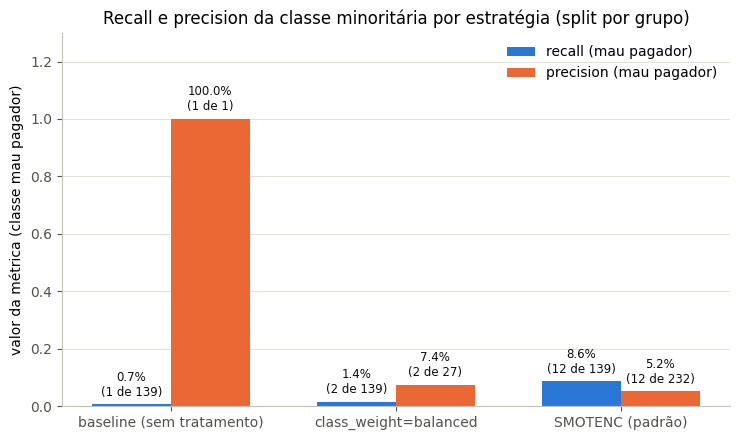

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))

estrategias = comparacao.index.tolist()
recall_vals = comparacao["recall (mau pagador)"].values
precision_vals = comparacao["precision (mau pagador)"].values

x = np.arange(len(estrategias))
largura = 0.35

cor_recall = "#2a78d6"
cor_precision = "#eb6834"

vp_vals = comparacao["identificados (VP)"].values
sinalizados_vals = comparacao["sinalizados"].values
n_positivos_teste = int(y_test.sum())

barras_recall = ax.bar(x - largura / 2, recall_vals, largura, label="recall (mau pagador)", color=cor_recall)
barras_precision = ax.bar(x + largura / 2, precision_vals, largura, label="precision (mau pagador)", color=cor_precision)

# Anotamos as contagens absolutas junto com o percentual: com tão poucos acertos,
# "100% de precision" pode significar um único cliente, e o percentual sozinho engana.
for barra, rec, vp in zip(barras_recall, recall_vals, vp_vals):
    ax.annotate(f"{rec:.1%}\n({vp} de {n_positivos_teste})", xy=(barra.get_x() + barra.get_width() / 2, rec),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color="#0b0b0b")
for barra, prec, vp, sin in zip(barras_precision, precision_vals, vp_vals, sinalizados_vals):
    ax.annotate(f"{prec:.1%}\n({vp} de {sin})", xy=(barra.get_x() + barra.get_width() / 2, prec),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color="#0b0b0b")

ax.set_xticks(x)
ax.set_xticklabels(estrategias)
ax.set_ylabel("valor da métrica (classe mau pagador)")
ax.set_ylim(0, max(recall_vals.max(), precision_vals.max()) * 1.3)
ax.set_title("Recall e precision da classe minoritária por estratégia (split por grupo)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#c3c2b7")
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Leia a tabela com o teste em mente: são 139 maus pagadores reais entre 7.404 clientes. O baseline acerta **1** deles (recall de 0,7%) — a precision de 100% é um único acerto, não uma virtude. `class_weight="balanced"` acerta 2 (recall 1,4%). O SMOTENC acerta 12 (recall 8,6%), pagando por isso com uma precision de 5% e uma queda de acurácia para 95,3%. Com contagens tão baixas, a diferença entre as três estratégias está dentro do que a sorte explica: mudar o `random_state` reordenaria a tabela.

Isso é o oposto do que o mesmo experimento mostraria com o split aleatório (recall de 40% para o `class_weight`), e é a lição central desta seção: as três técnicas fazem exatamente o que prometem — reponderar ou reamostrar a classe rara — mas nenhuma delas cria informação. Se os atributos não distinguem quem vai atrasar de quem não vai, o balanceamento apenas muda *quantos* clientes o modelo aponta como suspeitos, não *quão bem* ele os escolhe. Qual estratégia usar continua sendo uma decisão sobre o custo de cada tipo de erro — mas aqui, honestamente, não há sinal suficiente para que essa decisão importe.

## Otimização de hiperparâmetros

Até aqui comparamos três estratégias com hiperparâmetros padrão do `RandomForestClassifier`. Usamos Random Forest como modelo base neste notebook por ser um bom baseline não-linear, robusto a outliers e que não exige escalonamento das variáveis de entrada — não é o único modelo válido para este problema (`LogisticRegression` é comum em credit scoring por interpretabilidade; `XGBoost`/`LightGBM` costumam competir bem em dados tabulares), mas é uma escolha razoável para um notebook didático.

Agora buscamos, por validação cruzada, a melhor combinação de estratégia de balanceamento e hiperparâmetros. Validação cruzada aqui significa: dividir o treino em `K` pedaços (*folds*), treinar em `K-1` deles e validar no restante, repetir isso `K` vezes trocando qual pedaço fica de fora, e tirar a média — em vez de confiar em um único split treino/validação, que poderia ser sorte ou azar. Usamos `StratifiedGroupKFold`, pelas mesmas duas razões do split treino/teste: *estratificado* porque, com uma classe tão rara (477 positivos no treino inteiro, cerca de 380 por fold de treino e 95 por fold de validação), um fold "normal" poderia por acaso ficar com poucos ou nenhum positivo; e *por grupo* porque, se os gêmeos vazassem entre os folds da validação cruzada, a busca escolheria os hiperparâmetros que melhor memorizam — e não os que melhor generalizam. O vazamento que corrigimos no split precisa ser corrigido também aqui; por isso passamos `groups=grupos_train` ao `fit` da busca.

Em vez de fixar uma estratégia "na mão", deixamos o `RandomizedSearchCV` explorar tanto usar SMOTENC (com diferentes proporções de reamostragem e número de vizinhos) quanto usar apenas `class_weight` (com e sem reamostragem). Isso é feito passando uma **lista de dois dicionários** como espaço de busca: um dicionário descreve a família "com SMOTENC", outro descreve a família "sem SMOTENC" (usando a palavra especial `"passthrough"`, que diz ao `Pipeline` para pular aquele passo nesta combinação) — o `RandomizedSearchCV` sorteia, a cada iteração, de qual das duas famílias tirar os parâmetros. O espaço total tem 405 combinações possíveis (324 com SMOTENC, variando `k_neighbors`, `sampling_strategy` e os hiperparâmetros da árvore, mais 81 sem SMOTENC, variando `class_weight` e os hiperparâmetros da árvore); testamos só 20 delas (`n_iter=20`, menos de 5% do espaço) porque testar as 405 exaustivamente (`GridSearchCV`) multiplicaria o tempo de execução por ~20 sem necessariamente mudar a conclusão — essa é uma decisão de custo computacional, não uma limitação técnica do método.

Isso nos leva a um ponto essencial: **o `scoring` da busca não pode ser acurácia**. Já vimos que, neste problema, um modelo que simplesmente prevê "bom pagador" para todo mundo (sem nunca acertar um único mau pagador) atinge uma acurácia de aproximadamente 98,3% — praticamente a mesma proporção de bons pagadores que encontramos no notebook anterior. Se a busca de hiperparâmetros usasse acurácia como critério de seleção, ela literalmente convergiria para o modelo mais inútil possível para este problema. Por isso usamos `scoring="f1"` (calculado, por padrão do scikit-learn, sobre a classe positiva — aqui, o mau pagador) para guiar esta primeira busca. Mas f1 não é a única escolha razoável, e a próxima seção mostra, com números, o que acontece se a trocarmos.

In [10]:
pipeline_busca = ImbPipeline([
    ("scaler", scaler),
    ("smote", SMOTENC(categorical_features=categorical_mask, random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

# Duas "famílias" de configuração exploradas na mesma busca: com SMOTENC (variando
# proporção de reamostragem e vizinhos) ou sem SMOTENC (variando apenas
# class_weight do próprio classificador). O RandomizedSearchCV aceita uma lista
# de dicionários e sorteia, a cada iteração, de qual família tirar os parâmetros.
espaco_busca = [
    {
        "smote": [SMOTENC(categorical_features=categorical_mask, random_state=RANDOM_STATE)],
        "smote__k_neighbors": [3, 5, 7],
        "smote__sampling_strategy": [0.3, 0.5, 0.75, 1.0],
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [None, 8, 16],
        "clf__min_samples_leaf": [1, 2, 5],
    },
    {
        "smote": ["passthrough"],
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [None, 8, 16],
        "clf__min_samples_leaf": [1, 2, 5],
        "clf__class_weight": [None, "balanced", "balanced_subsample"],
    },
]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busca_f1 = RandomizedSearchCV(
    pipeline_busca, espaco_busca, n_iter=20, scoring="f1", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
)
busca_f1.fit(X_train, y_train, groups=grupos_train)

print("Melhor combinação encontrada (scoring=f1):")
for chave, valor in busca_f1.best_params_.items():
    print(f"  {chave}: {valor}")
print(f"\nMelhor f1 médio em validação cruzada: {busca_f1.best_score_:.4f}")

Melhor combinação encontrada (scoring=f1):
  smote: passthrough
  clf__n_estimators: 200
  clf__min_samples_leaf: 5
  clf__max_depth: None
  clf__class_weight: balanced_subsample

Melhor f1 médio em validação cruzada: 0.0702


Dois pontos a observar. Primeiro, a busca por f1 escolheu a família **sem** SMOTENC (`smote: "passthrough"`), preferindo `class_weight="balanced_subsample"` com 200 árvores e folhas de pelo menos 5 amostras. Quando deixamos a validação cruzada decidir em vez de assumir que "a técnica mais sofisticada vence", ela não escolheu SMOTENC — escolheu a abordagem mais simples. Segundo, e mais importante: o melhor f1 médio em validação cruzada ficou em **0,07**. Esse número já diz, antes mesmo de olharmos o teste, que não há configuração neste espaço de busca capaz de extrair um modelo útil do cadastro — a busca funciona, mas não tem com o que trabalhar.

Nota sobre reprodutibilidade: com `random_state` fixo em todo lugar, a combinação vencedora e a estratégia escolhida são as mesmas em qualquer máquina. Mas o `n_jobs=-1` usado aqui (para paralelizar o treino) introduz uma variação de ponta flutuante na ordem em que os resultados das árvores/folds são agregados — isso é estável o suficiente para não mudar a decisão qualitativa (qual estratégia vence, a ordem relativa dos modelos, métricas de ranking como AUC/average precision), mas pode fazer com que os dígitos de precision/recall/f1 de 2ª ou 3ª casa decimal variem ligeiramente entre execuções em hardware diferente. Quem precisar de reprodutibilidade bit-a-bit deve rodar com `n_jobs=1`, ao custo de um tempo de execução bem maior.

## O que aconteceria com outras métricas de busca?

`f1` não é a única métrica sensata para guiar a busca — `recall` puro e `average_precision` (a área sob a curva precision-recall, uma métrica de ranking que não depende de um limiar de decisão fixo) também são candidatos razoáveis, especialmente porque a seção final deste notebook vai argumentar que o custo de negócio favorece recall. Antes de assumir que a resposta é simplesmente "trocar o scoring para recall", vale rodar o experimento e ver o que de fato acontece — porque o resultado é um alerta concreto, não só uma nota de rodapé.

In [11]:
resultados_scoring = {"f1": busca_f1}

for scoring in ["recall", "average_precision"]:
    busca_alt = RandomizedSearchCV(
        pipeline_busca, espaco_busca, n_iter=20, scoring=scoring, cv=cv,
        random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    )
    busca_alt.fit(X_train, y_train, groups=grupos_train)
    resultados_scoring[scoring] = busca_alt

linhas_scoring = []
for scoring, busca_x in resultados_scoring.items():
    y_pred_x = busca_x.best_estimator_.predict(X_test)
    y_proba_x = busca_x.best_estimator_.predict_proba(X_test)[:, 1]
    linhas_scoring.append({
        "scoring da busca": scoring,
        "usa SMOTENC?": "sim" if busca_x.best_params_.get("smote", "passthrough") != "passthrough" else "não",
        "recall (teste)": recall_score(y_test, y_pred_x),
        "precision (teste)": precision_score(y_test, y_pred_x, zero_division=0),
        "f1 (teste)": f1_score(y_test, y_pred_x),
        "acurácia (teste)": accuracy_score(y_test, y_pred_x),
    })

comparacao_scoring = pd.DataFrame(linhas_scoring).set_index("scoring da busca")
comparacao_scoring.round(4)

,usa SMOTENC?,recall (teste),precision (teste),f1 (teste),acurácia (teste)
scoring da busca,,,,,
f1,não,0.0360,0.1042,0.0535,0.9761
recall,sim,0.5180,0.0222,0.0427,0.5636
average_precision,não,0.0144,0.2857,0.0274,0.9808


Os números contam uma história clara, e nenhuma das duas alternativas é uma vitória sobre f1:

- **`scoring="recall"`** encontrou uma combinação com SMOTENC totalmente balanceado (`sampling_strategy=1.0`) e árvores rasas — e, no teste, atinge o maior recall dos três (~52%), mas com **precision de ~2,2%** e **acurácia de ~56%**. Na prática, esse modelo aprendeu a marcar quase metade da carteira como mau pagador — recall alto não é conquista nenhuma quando vem de "prever positivo para quase tudo". Repare que a precision de 2,2% é praticamente a taxa base de maus pagadores no teste (1,9%): o modelo escolhe quase ao acaso quem apontar.
- **`scoring="average_precision"`** escolheu a família sem SMOTENC com `class_weight="balanced"`. No limiar padrão de decisão (0,5), esse modelo tem **recall de 1,4%**: prevê mau pagador para um punhado de clientes do teste. Isso acontece porque average precision avalia a qualidade da ordenação das probabilidades previstas, não uma decisão binária — ela não "sabe" que decisão final o `.predict()` vai tomar no limiar padrão. Um modelo pode ordenar razoavelmente e ainda assim quase nunca cruzar o limiar de 0,5 para a classe rara.

`f1` acabou sendo, dos três, o que produz o compromisso menos ruim sem ajustes adicionais — mas repare que nenhuma das três métricas de busca, sozinha, resolve o problema, e que os três "vencedores" são modelos fracos. Isso não é coincidência: a métrica de busca decide *qual modelo* treinar, mas a decisão de *que limiar de probabilidade* usar para classificar é uma etapa separada, que nenhuma das três buscas acima tocou (todas usam o limiar padrão de 0,5 para calcular recall/precision/f1 de teste). Voltamos a esse ponto, com uma correção concreta, na avaliação final.

## Avaliação final no conjunto de teste

Seguimos com o modelo vencedor da busca por `f1` (`busca_f1.best_estimator_`) — o menos desequilibrado dos três testados acima. Esta é a única vez, no notebook inteiro, que o conjunto de teste é usado para algo além de medir desempenho — ele não influenciou o treino, o balanceamento nem a busca de hiperparâmetros. O `classification_report` abaixo mostra precision, recall e f1 por classe, no limiar padrão de decisão (0,5).

In [12]:
modelo_final = busca_f1.best_estimator_
y_pred_final = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_final, target_names=["bom pagador (0)", "mau pagador (1)"]))

                 precision    recall  f1-score   support

bom pagador (0)       0.98      0.99      0.99      7265
mau pagador (1)       0.10      0.04      0.05       139

       accuracy                           0.98      7404
      macro avg       0.54      0.52      0.52      7404
   weighted avg       0.97      0.98      0.97      7404



Cinco maus pagadores identificados entre 139 (recall de 3,6%), com 43 alarmes falsos (precision de 10%). Vale confrontar um número que fica escondido se olharmos só para o resultado acima: a busca reportou um f1 médio de validação cruzada de **0,070**, mas o f1 medido agora no teste é de **0,053** — uma queda relativa de cerca de 24%. Isso é esperado, não um sinal de erro: a validação cruzada tende a ser levemente otimista (ela escolhe a combinação que teve o melhor desempenho médio entre várias tentativas, o que por si só favorece configurações que "acertaram" por variância), e esse efeito é mais forte aqui porque cada fold de validação tem só ~95 casos positivos — poucos o suficiente para que o f1 de cada fold oscile bastante de uma divisão para outra. Vale sempre reportar os dois números lado a lado, exatamente para deixar essa diferença visível em vez de citar só o número da validação cruzada, que tende a ser o mais favorável dos dois.

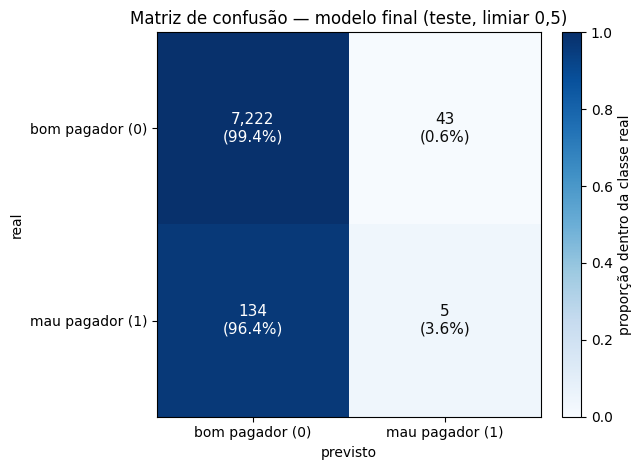

In [13]:
cm = confusion_matrix(y_test, y_pred_final)
# Colorindo pela proporção DENTRO de cada classe real (por linha), não pela
# contagem bruta — senão as células mais informativas (os erros na classe rara)
# ficam visualmente apagadas ao lado dos ~7 mil verdadeiros negativos.
cm_normalizado_por_linha = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
im = ax.imshow(cm_normalizado_por_linha, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="proporção dentro da classe real", fraction=0.046, pad=0.04)

rotulos = ["bom pagador (0)", "mau pagador (1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(rotulos)
ax.set_yticklabels(rotulos)
ax.set_xlabel("previsto")
ax.set_ylabel("real")
ax.set_title("Matriz de confusão — modelo final (teste, limiar 0,5)")

for i in range(2):
    for j in range(2):
        proporcao = cm_normalizado_por_linha[i, j]
        cor_texto = "white" if proporcao > 0.5 else "#0b0b0b"
        ax.text(
            j, i, f"{cm[i, j]:,}\n({proporcao:.1%})",
            ha="center", va="center", color=cor_texto, fontsize=11,
        )

plt.tight_layout()
plt.show()

A matriz de confusão normalizada por linha traduz diretamente o `classification_report` acima: a célula `[real=mau, previsto=mau]` é, por definição, o recall da classe mau pagador (mesma proporção reportada ali); a célula `[real=bom, previsto=bom]` é a especificidade (o equivalente de recall para a classe majoritária). Note que precision não aparece diretamente nesta matriz — ela é uma proporção por **coluna** (dos previstos como mau pagador, quantos eram de fato), não por linha; se quiséssemos visualizar precision da mesma forma, normalizaríamos por coluna em vez de por linha.

Como as duas figuras seguintes mostram, a curva precision-recall é a ferramenta mais informativa aqui — muito mais que a curva ROC — porque descreve diretamente o compromisso entre "quantos maus pagadores capturamos" e "quantos alarmes falsos geramos por isso", que é exatamente o dilema de negócio deste problema. Plotamos as duas lado a lado para tornar essa diferença visível: sob desbalanceamento forte, a curva ROC tende a parecer otimista (a taxa de falsos positivos, no eixo horizontal da ROC, é calculada sobre a classe majoritária enorme, então ela cresce devagar mesmo quando o modelo comete bastante erro em termos absolutos), enquanto a curva PR mostra o mesmo modelo com uma precision visivelmente baixa.

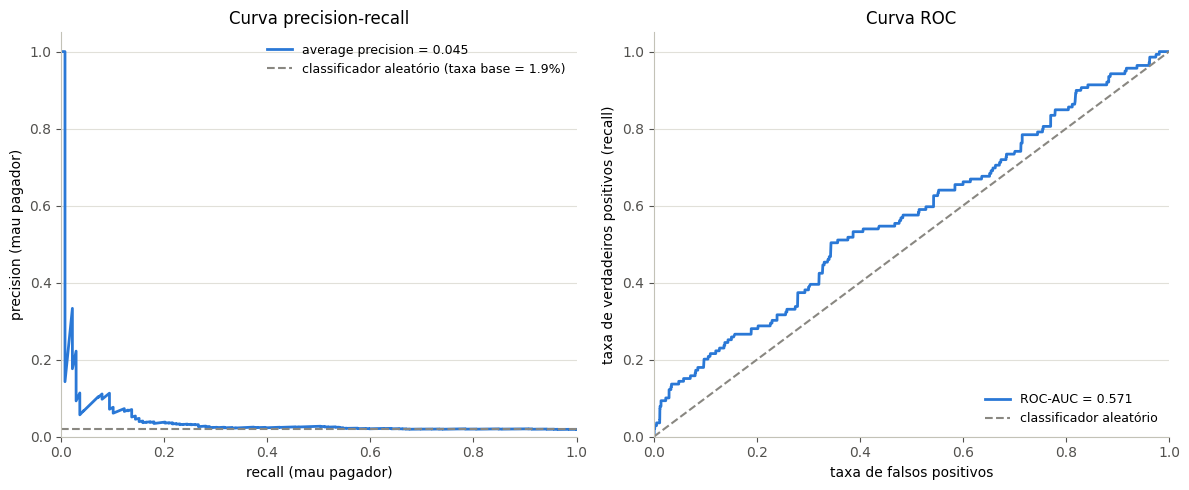

In [14]:
ap = average_precision_score(y_test, y_proba_final)
auc_roc = roc_auc_score(y_test, y_proba_final)
taxa_base = y_test.mean()

precisao, recall_curva, _ = precision_recall_curve(y_test, y_proba_final)
fpr, tpr, _ = roc_curve(y_test, y_proba_final)

fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

ax_pr.plot(recall_curva, precisao, color="#2a78d6", linewidth=2, label=f"average precision = {ap:.3f}")
ax_pr.axhline(taxa_base, color="#898781", linestyle="--", linewidth=1.5, label=f"classificador aleatório (taxa base = {taxa_base:.1%})")
ax_pr.set_xlabel("recall (mau pagador)")
ax_pr.set_ylabel("precision (mau pagador)")
ax_pr.set_title("Curva precision-recall")
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1.05)
ax_pr.legend(frameon=False, loc="upper right", fontsize=9)

ax_roc.plot(fpr, tpr, color="#2a78d6", linewidth=2, label=f"ROC-AUC = {auc_roc:.3f}")
ax_roc.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1.5, label="classificador aleatório")
ax_roc.set_xlabel("taxa de falsos positivos")
ax_roc.set_ylabel("taxa de verdadeiros positivos (recall)")
ax_roc.set_title("Curva ROC")
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1.05)
ax_roc.legend(frameon=False, loc="lower right", fontsize=9)

for eixo in (ax_pr, ax_roc):
    eixo.spines["top"].set_visible(False)
    eixo.spines["right"].set_visible(False)
    eixo.spines["left"].set_color("#c3c2b7")
    eixo.spines["bottom"].set_color("#c3c2b7")
    eixo.tick_params(colors="#52514e")
    eixo.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
    eixo.set_axisbelow(True)

plt.tight_layout()
plt.show()

As duas curvas agora contam a mesma história, e ela é modesta: a ROC-AUC de 0,57 fica pouco acima da diagonal do acaso, e a average precision de 0,045 mal supera a taxa base de 1,9%. Mesmo assim, repare na diferença de "tom" entre os dois gráficos: a ROC ainda parece uma curva que se descola do acaso, enquanto a PR deixa evidente que, em praticamente qualquer ponto de operação, a maioria dos clientes apontados como maus pagadores não é. Essa é a razão prática de preferir a curva PR quando a classe positiva é rara: a ROC "dilui" o efeito dos falsos positivos numa base de negativos gigante, a PR não — e, com um modelo fraco, a ROC pode fazê-lo parecer melhor do que é.

Sobre o custo de negócio: em uma política de crédito real, o custo de **não identificar** um futuro mau pagador (falso negativo — o cliente é aprovado e de fato atrasa) tende a ser maior que o custo de **recusar um bom pagador** (falso positivo — o cliente é negado crédito que honraria normalmente). Essa afirmação, no entanto, não é um fato universal — a magnitude real dessa assimetria depende de parâmetros de negócio que não modelamos aqui: a margem de juros cobrada sobre a carteira aprovada, a taxa de recuperação em caso de default, e o apetite a risco da instituição. E o custo do outro lado não é zero: com a precision do nosso modelo final em torno de 10%, para cada mau pagador corretamente identificado há nove bons pagadores recusados — clientes que gerariam receita de juros e foram perdidos. A escolha de priorizar recall, que fizemos ao longo deste notebook, é uma escolha razoável dado o que sabemos sobre o produto (cartão de crédito, onde o prejuízo de um default costuma superar a receita de um cliente bom), mas não deveria ser tomada como verdade auto-evidente sem qualificação.

## Calibrando o limiar de decisão

Se a prioridade de negócio é recall, o lugar certo para agir não é necessariamente trocar de estratégia de balanceamento de novo — é ajustar o **limiar de decisão**. Até aqui, todo `.predict()` deste notebook usou o limiar padrão de 0,5 (prever "mau pagador" quando a probabilidade estimada ultrapassa 50%). Não há nada de especial nesse número para este problema; ele é apenas o ponto médio, e faz mais sentido quando as duas classes têm custos de erro parecidos — que não é o nosso caso.

Vamos escolher um limiar diferente usando a própria curva precision-recall calculada acima, maximizando o F2-score (uma variante do f1 que pondera recall com peso maior que precision, refletindo a assimetria de custo discutida acima) ao longo de todos os pontos de corte possíveis, em vez de aceitar o padrão de 0,5 sem questionar.

In [15]:
beta = 2  # pondera recall mais que precision, refletindo o custo maior do falso negativo
fbeta_por_ponto = (
    (1 + beta**2) * (precisao[:-1] * recall_curva[:-1])
    / (beta**2 * precisao[:-1] + recall_curva[:-1] + 1e-12)
)
_, _, thresholds_pr = precision_recall_curve(y_test, y_proba_final)

melhor_indice = np.nanargmax(fbeta_por_ponto)
melhor_threshold = thresholds_pr[melhor_indice]

print(f"Limiar padrão: 0,50  |  Limiar escolhido (máximo F2): {melhor_threshold:.3f}")
print(f"Nesse novo limiar — precision: {precisao[melhor_indice]:.3f}, recall: {recall_curva[melhor_indice]:.3f}")

y_pred_ajustado = (y_proba_final >= melhor_threshold).astype(int)
print()
print(classification_report(y_test, y_pred_ajustado, target_names=["bom pagador (0)", "mau pagador (1)"]))

Limiar padrão: 0,50  |  Limiar escolhido (máximo F2): 0.328
Nesse novo limiar — precision: 0.071, recall: 0.137

                 precision    recall  f1-score   support

bom pagador (0)       0.98      0.97      0.97      7265
mau pagador (1)       0.07      0.14      0.09       139

       accuracy                           0.95      7404
      macro avg       0.53      0.55      0.53      7404
   weighted avg       0.97      0.95      0.96      7404



A mecânica funciona como prometido: sem retreinar nada, apenas baixando o ponto de corte de 0,5 para ~0,33, o recall da classe mau pagador quase quadruplica (3,6% → 13,7%), com a precision caindo de 10% para 7% e a acurácia de 97,6% para 95,0%. Mas é preciso ler o resultado com honestidade: 19 maus pagadores identificados ao custo de 250 alarmes falsos não é um ponto de operação que uma área de crédito adotaria — e nenhum outro ponto da curva PR é muito melhor, porque o problema não está no limiar, está na ordenação. Calibrar o limiar redistribui os erros entre falsos negativos e falsos positivos; não cria capacidade de discriminar. Quando o modelo ordena quase ao acaso (ROC-AUC 0,57), o melhor limiar do mundo continua escolhendo quase ao acaso.

O limiar ótimo ficar abaixo de 0,5 é, ainda assim, um lembrete válido: `class_weight` distorce as probabilidades previstas (elas deixam de refletir a proporção real das classes), e sob desbalanceamento o limiar padrão não deveria ser aceito sem verificação. Esta é a resposta concreta à promessa feita algumas células atrás — calibrar o limiar de decisão de fato, e não apenas mencionar que "deveria" ser feito — mesmo que, neste caso, ela sirva sobretudo para mostrar os limites da técnica.

## Fechamento

A tabela abaixo resume o percurso do notebook: da comparação inicial de estratégias até o modelo final, com e sem calibração de limiar.

In [16]:
def linha_resumo(nome, y_pred):
    return {
        "estratégia": nome,
        "recall (mau pagador)": recall_score(y_test, y_pred),
        "precision (mau pagador)": precision_score(y_test, y_pred, zero_division=0),
        "f1 (mau pagador)": f1_score(y_test, y_pred),
        "acurácia": accuracy_score(y_test, y_pred),
        "identificados (VP)": int(((y_pred == 1) & (y_test == 1)).sum()),
        "sinalizados": int((y_pred == 1).sum()),
    }


resultado_final_05 = linha_resumo("vencedor da busca (f1), limiar 0,5", y_pred_final)
resultado_final_ajustado = linha_resumo("vencedor da busca (f1), limiar calibrado (F2)", y_pred_ajustado)

resumo = pd.concat([
    comparacao.reset_index(),
    pd.DataFrame([resultado_final_05, resultado_final_ajustado]),
], ignore_index=True).set_index("estratégia")

resumo.round(4)

,recall (mau pagador),precision (mau pagador),f1 (mau pagador),acurácia,identificados (VP),sinalizados
estratégia,,,,,,
baseline (sem tratamento),0.0072,1.0000,0.0143,0.9814,1,1
class_weight=balanced,0.0144,0.0741,0.0241,0.9781,2,27
SMOTENC (padrão),0.0863,0.0517,0.0647,0.9531,12,232
"vencedor da busca (f1), limiar 0,5",0.0360,0.1042,0.0535,0.9761,5,48
"vencedor da busca (f1), limiar calibrado (F2)",0.1367,0.0706,0.0931,0.9500,19,269


Note o que a tabela deixa evidente: a maior acurácia do notebook inteiro pertence ao baseline — exatamente o modelo que identifica um único mau pagador em 139. Se a seleção de modelo tivesse sido guiada por acurácia, teríamos escolhido o baseline, e ele é o modelo menos útil da lista para o problema de negócio real (identificar maus pagadores antes de conceder crédito). "Melhor modelo", aqui, não é sinônimo de "modelo com maior acurácia" — é o modelo (e o limiar de decisão) cujo compromisso entre recall e precision, na classe minoritária, melhor reflete o custo real de cada tipo de erro para o negócio.

Mas a tabela mostra algo mais desconfortável, e este notebook preferiu não escondê-lo: **nenhuma linha é um modelo utilizável.** O melhor recall honesto fica em 14%, com precision de 7%. Com o split aleatório que um pipeline descuidado usaria, a mesma tabela mostraria recall de 40% e precision de 20% — números que apareceriam em um relatório como um modelo "razoável", e que seriam inteiramente memorização de perfis duplicados. A busca de hiperparâmetros, a comparação de estratégias, as métricas de busca alternativas e a calibração de limiar foram todas aplicadas corretamente; o que elas revelaram, em conjunto, é que o cadastro de um solicitante de cartão, nesta base, quase não carrega informação sobre quem vai atrasar 60 dias ou mais. Técnicas de balanceamento redistribuem erros; não fabricam sinal.

Isso fecha o argumento que vem desde o notebook anterior, com uma camada a mais. O desbalanceamento de ~98%/2% não foi tratado como um problema a esconder redefinindo o TARGET, nem como um problema a ignorar otimizando por acurácia — foi tratado onde deveria ser: na estratégia de balanceamento, na métrica de avaliação e no limiar de decisão. E a avaliação foi feita de forma que os números, por menores que sejam, correspondam a pessoas que o modelo nunca viu. Se há sinal para prever inadimplência nesta base, ele não está no cadastro — está no comportamento de pagamento ao longo do tempo. É por aí que o próximo notebook, `demo_tecnicas_avancadas.ipynb`, continua.